# Processamento Digital de Imagens (PDI)
## Atividade 2: Transformações no Domínio Espacial e da Frequência

**Aluno(a):** Nome do Aluno  
**Matrícula:** 00000000  
**Data de Entrega:** 29/10  
**Tema do Trabalho Final:** Gastronomia

---

### Diretrizes e Regras Gerais
* **OpenCV (`cv2`):** Utilizado apenas para carregar (`cv2.imread`) e salvar imagens.
* **Implementações Manuais:** Todas as operações espaciais (convolução 2D, tratamento de bordas e filtros $h_1$ a $h_11$) e máscaras de frequência foram implementadas manualmente com **NumPy**.
* **FFT:** Conforme autorizado, a Transformada Rápida de Fourier foi calculada com a biblioteca padrão `numpy.fft`.


In [1]:
# 0. Configuração do Ambiente e Carregamento de Imagens
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 9
plt.rcParams['image.cmap'] = 'gray'

def rgb2gray(img_bgr: np.ndarray) -> np.ndarray:
    """Conversão manual BGR para níveis de cinza (ITU-R BT.601)."""
    if img_bgr.ndim == 2:
        return img_bgr.copy()
    b, g, r = img_bgr[:, :, 0], img_bgr[:, :, 1], img_bgr[:, :, 2]
    return np.clip(0.299 * r + 0.587 * g + 0.114 * b, 0, 255).astype(np.uint8)

def load_image(path: str, size=(512, 512)) -> np.ndarray:
    """Carrega a imagem e converte para tons de cinza com tamanho padronizado."""
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        raise FileNotFoundError(f"Imagem não encontrada: {path}")
    if size is not None:
        img_bgr = cv2.resize(img_bgr, size, interpolation=cv2.INTER_AREA)
    return rgb2gray(img_bgr)


---
## 1. Questão 1 — Filtragem no Domínio Espacial (Kernels $h_1$ a $h_{11}$)

A filtragem espacial linear calcula o novo valor de cada pixel por meio da convolução discreta bidimensional com uma máscara $w$ de tamanho $m \times n$:

$$g(x, y) = \sum_{s=-a}^{a} \sum_{t=-b}^{b} w(s, t) \, f(x - s, y - t)$$

Para matrizes com coeficientes negativos (derivativos), a saída foi normalizada linearmente em $[0, 255]$ para visualização adequada das bordas e transições.


In [2]:
# 1.1 Convolução 2D Manual e Definição dos Kernels h1 a h11

def convolve2d_manual(image: np.ndarray, kernel: np.ndarray, normalize: bool = False) -> np.ndarray:
    """
    Executa a convolução discreta 2D manual com padding reflexivo nas bordas.
    Inverte o kernel em 180° (convolução matemática estrita).
    """
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    img_padded = np.pad(image.astype(np.float64), ((pad_h, pad_h), (pad_w, pad_w)), mode='reflect')
    k_rot = kernel[::-1, ::-1].astype(np.float64)
    
    H, W = image.shape
    output = np.zeros((H, W), dtype=np.float64)
    for i in range(k_h):
        for j in range(k_w):
            output += k_rot[i, j] * img_padded[i:i + H, j:j + W]
            
    if normalize:
        min_v, max_v = output.min(), output.max()
        if max_v > min_v:
            return np.round(((output - min_v) / (max_v - min_v)) * 255.0).astype(np.uint8)
        return np.zeros_like(image, dtype=np.uint8)
    return np.clip(np.round(output), 0, 255).astype(np.uint8)

# Dicionário com os 11 kernels descritos no enunciado
kernels = {
    "h1": (np.array([[0,0,-1,0,0],[0,-1,-2,-1,0],[-1,-2,16,-2,-1],[0,-1,-2,-1,0],[0,0,-1,0,0]]), True, "Laplaciano 5x5"),
    "h2": ((1/256) * np.array([[1,4,6,4,1],[4,16,24,16,4],[6,24,36,24,6],[4,16,24,16,4],[1,4,6,4,1]]), False, "Gaussiano 5x5"),
    "h3": (np.array([[-1,0,1],[-2,0,2],[-1,0,1]]), True, "Sobel Vertical (Gx)"),
    "h4": (np.array([[-1,-2,-1],[0,0,0],[1,2,1]]), True, "Sobel Horizontal (Gy)"),
    "h5": (np.array([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]]), True, "Laplaciano 3x3"),
    "h6": ((1/9) * np.ones((3,3)), False, "Média 3x3"),
    "h7": (np.array([[-1,-1,2],[-1,2,-1],[2,-1,-1]]), True, "Linhas +45°"),
    "h8": (np.array([[2,-1,-1],[-1,2,-1],[-1,-1,2]]), True, "Linhas -45°"),
    "h9": ((1/9) * np.eye(9), False, "Motion Blur 9x9"),
    "h10": ((1/8) * np.array([[-1,-1,-1,-1,-1],[-1,2,2,2,-1],[-1,2,8,2,-1],[-1,2,2,2,-1],[-1,-1,-1,-1,-1]]), False, "Realce High-Boost 5x5"),
    "h11": (np.array([[-1,-1,0],[-1,0,1],[0,1,1]]), True, "Relevo (Emboss)")
}


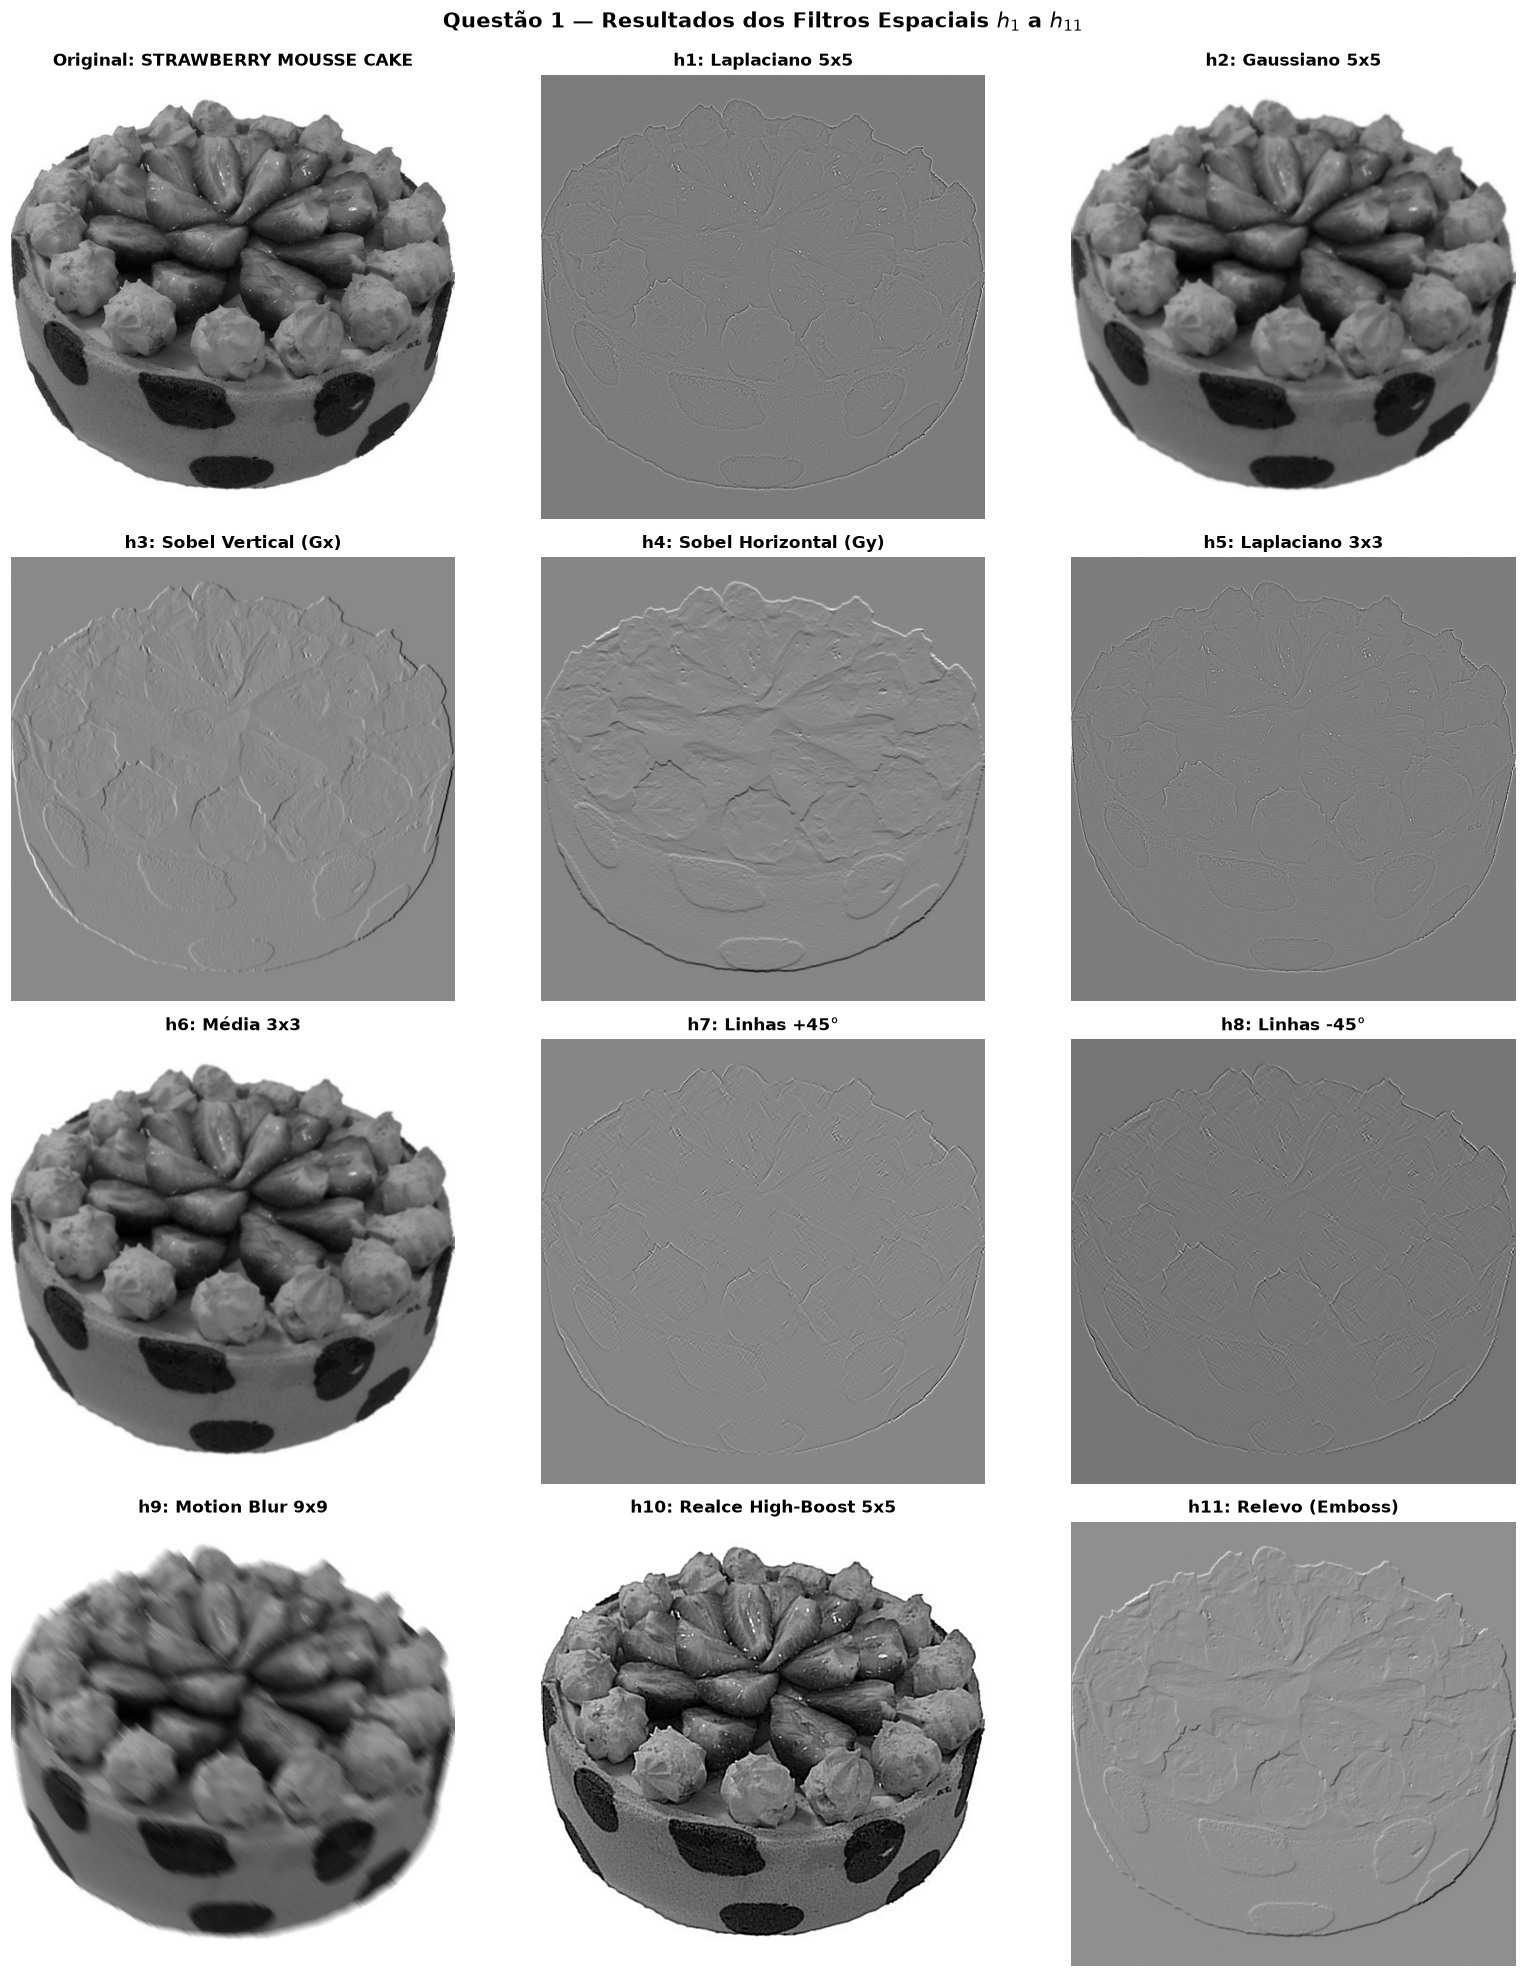

In [3]:
# 1.2 Aplicação e Visualização dos Filtros h1 a h11

img_cake1_path = os.path.join("Images", 'STRAWBERRY MOUSSE CAKE', '03.jpg')
img_cake1 = load_image(img_cake1_path)

# Executa todos os filtros
results_h = {k: convolve2d_manual(img_cake1, data[0], normalize=data[1]) for k, data in kernels.items()}

# Exibição compacta em grade 4x3 (Original + 11 filtros)
fig, axes = plt.subplots(4, 3, figsize=(15, 18))
axes = axes.flatten()

axes[0].imshow(img_cake1, cmap='gray')
axes[0].set_title(f"Original: {'STRAWBERRY MOUSSE CAKE'}", fontweight='bold')
axes[0].axis('off')

for idx, (k, data) in enumerate(kernels.items(), start=1):
    axes[idx].imshow(results_h[k], cmap='gray')
    axes[idx].set_title(f"{k}: {data[2]}", fontweight='bold')
    axes[idx].axis('off')

plt.suptitle(f"Questão 1 — Resultados dos Filtros Espaciais $h_1$ a $h_{{11}}$", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


### 1.3 Interpretação e Análise dos Efeitos Espaciais

* **Suavização / Passa-Baixas ($h_2$, $h_6$, $h_9$):**
  - **Média $3\times 3$ ($h_6$):** Reduz ruídos e granulações locais substituindo o pixel pela média da vizinhança.
  - **Gaussiano $5\times 5$ ($h_2$):** Suavização mais natural e isotrópica devido aos pesos ponderados em sino.
  - **Motion Blur $9\times 9$ ($h_9$):** Simula desfoque direcional ao longo da diagonal devido aos pesos concentrados na diagonal principal.
* **Detecção de Bordas por 1ª Derivada ($h_3$, $h_4$):**
  - **Sobel Vertical $h_3$ ($G_x$):** Destaca gradientes horizontais (arestas verticais do bolo e confeitos).
  - **Sobel Horizontal $h_4$ ($G_y$):** Destaca gradientes verticais (camadas horizontais de recheio e base do prato).
* **Derivadas de 2ª Ordem e Realce ($h_1$, $h_5$, $h_{10}$):**
  - **Laplaciano $3\times 3$ ($h_5$) e $5\times 5$ ($h_1$):** Realçam descontinuidades e transições bruscas omnidirecionais.
  - **High-Boost $h_{10}$:** Preserva o nível médio de cinza enquanto acentua texturas finas (efeito nítido de *sharpening*).
* **Filtros Direcionais e Especiais ($h_7$, $h_8$, $h_{11}$):**
  - **$h_7$ e $h_8$:** Isolam linhas orientadas a $+45^\circ$ e $-45^\circ$, respectivamente.
  - **Relevo $h_{11}$ (*Emboss*):** Produz efeito tridimensional de luz e sombra direcional.


---
## 2. Questão 2 — Filtragem e Compressão no Domínio da Frequência (FFT)

### 2.1 Metodologia do Domínio da Frequência
Conforme orientado no enunciado, o pipeline de filtragem segue 7 etapas:
1. Obtenção da imagem em escala de cinza;
2. Transformada Rápida de Fourier 2D (`np.fft.fft2`);
3. Centralização da frequência zero via `np.fft.fftshift`;
4. Construção das máscaras circulares baseadas na distância euclidiana $D(u, v)$ ao centro;
5. Multiplicação pontual $G(u, v) = F(u, v) \cdot H(u, v)$;
6. Transformada Inversa (`np.fft.ifftshift` + `np.fft.ifft2`);
7. Análise dos resultados e das imagens recuperadas.


In [4]:
# 2.1 Pipeline de Filtragem no Domínio da Frequência

def create_circular_mask(shape: tuple[int, int], filter_type: str, d0: float, width: float = 30.0) -> np.ndarray:
    """Gera as máscaras analíticas ideais para o domínio de frequência."""
    M, N = shape
    u, v = np.ogrid[:M, :N]
    D = np.sqrt((u - M / 2.0)**2 + (v - N / 2.0)**2)
    
    if filter_type == 'passa-baixa':
        return (D <= d0).astype(np.float64)
    elif filter_type == 'passa-alta':
        return (D > d0).astype(np.float64)
    elif filter_type == 'passa-faixa':
        return ((D >= (d0 - width / 2.0)) & (D <= (d0 + width / 2.0))).astype(np.float64)
    elif filter_type == 'rejeita-faixa':
        return (~((D >= (d0 - width / 2.0)) & (D <= (d0 + width / 2.0)))).astype(np.float64)
    raise ValueError(f"Filtro desconhecido: {filter_type}")

def apply_fft_filter(img: np.ndarray, mask: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Aplica a máscara no espectro centralizado e retorna a imagem reconstruída e o espectro filtrado."""
    F = np.fft.fft2(img.astype(np.float64))
    F_shift = np.fft.fftshift(F)
    G_shift = F_shift * mask
    g = np.real(np.fft.ifft2(np.fft.ifftshift(G_shift)))
    return np.clip(np.round(g), 0, 255).astype(np.uint8), G_shift


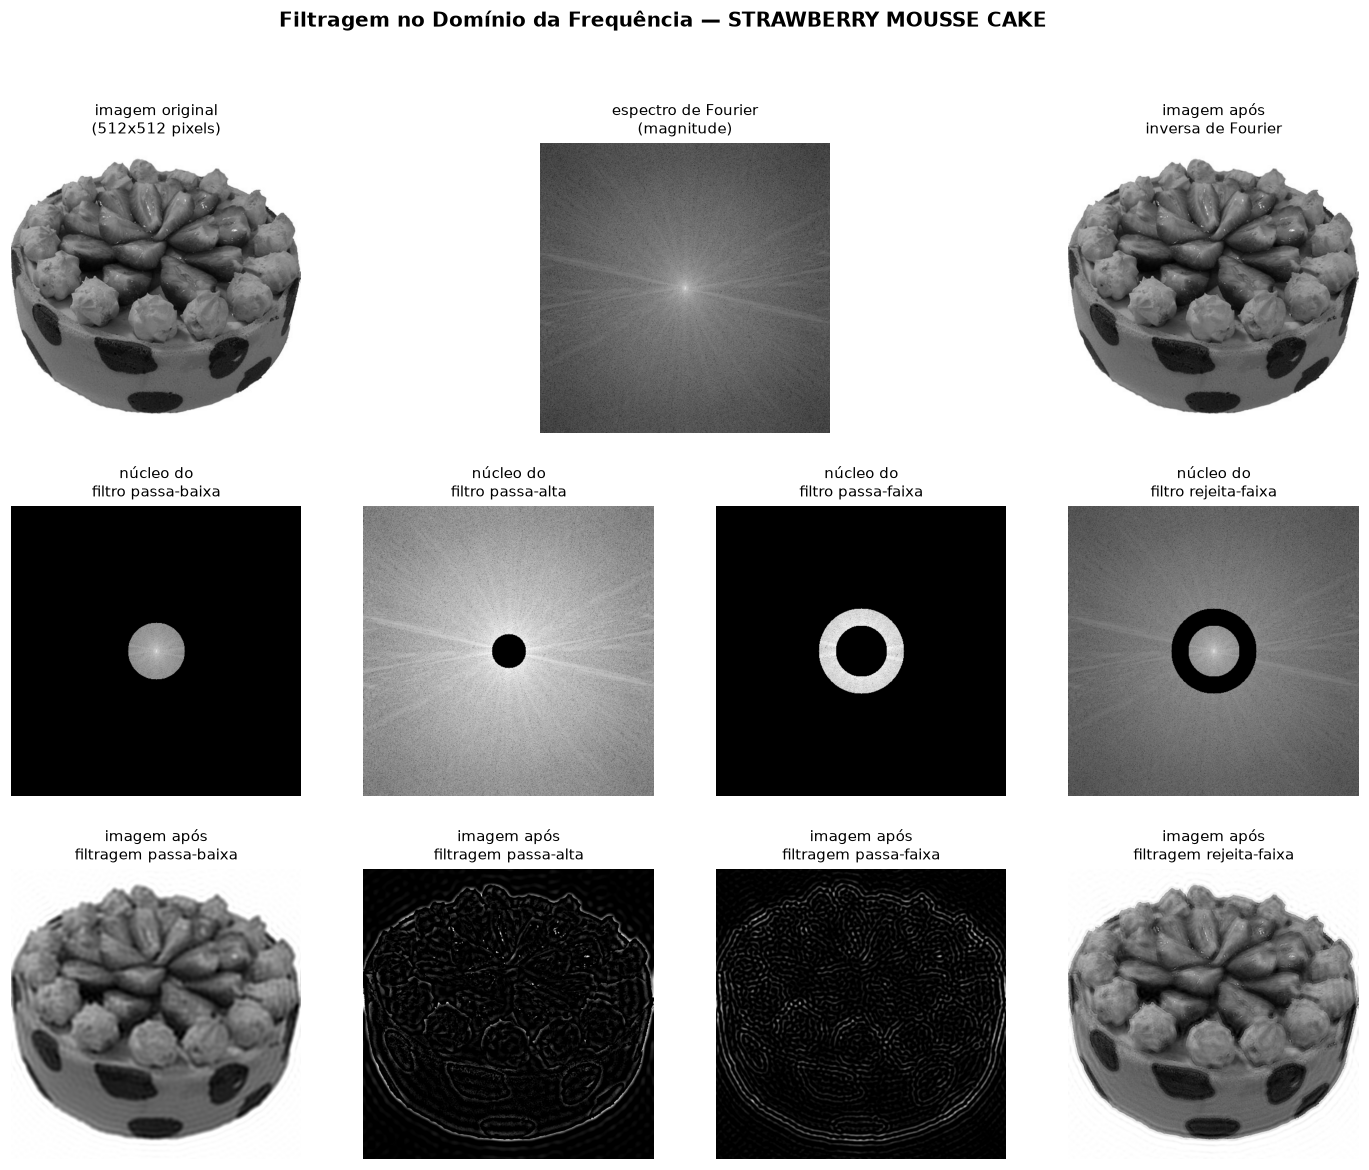

In [5]:
# 2.2 Visualização Completa da Filtragem na Frequência (Layout do PDF)

# Aplica FFT direta na imagem
F = np.fft.fft2(img_cake1.astype(np.float64))
F_shift = np.fft.fftshift(F)
spectrum_log = np.log(1.0 + np.abs(F_shift))
img_reconstructed = np.clip(np.round(np.real(np.fft.ifft2(F))), 0, 255).astype(np.uint8)

# Parâmetros dos núcleos
d0_lp, d0_hp, d0_bp, w_bp = 50.0, 30.0, 60.0, 30.0
filter_types = ['passa-baixa', 'passa-alta', 'passa-faixa', 'rejeita-faixa']
masks = [
    create_circular_mask(img_cake1.shape, 'passa-baixa', d0=d0_lp),
    create_circular_mask(img_cake1.shape, 'passa-alta', d0=d0_hp),
    create_circular_mask(img_cake1.shape, 'passa-faixa', d0=d0_bp, width=w_bp),
    create_circular_mask(img_cake1.shape, 'rejeita-faixa', d0=d0_bp, width=w_bp)
]

filtered_imgs = []
for m, t in zip(masks, filter_types):
    img_filt, _ = apply_fft_filter(img_cake1, m)
    # Para passa-alta e passa-faixa, reforçamos contraste para visualização das bordas
    if t in ['passa-alta', 'passa-faixa']:
        img_filt = np.clip(img_filt.astype(float) * 2.5, 0, 255).astype(np.uint8)
    filtered_imgs.append(img_filt)

# Painel estruturado exatamente conforme o layout do PDF
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 4, height_ratios=[1, 1, 1], hspace=0.25, wspace=0.15)

# Linha 1: Imagem Original, Espectro de Fourier, Imagem após inversa de Fourier
ax0 = fig.add_subplot(gs[0, 0])
ax0.imshow(img_cake1, cmap='gray')
ax0.set_title(f"imagem original\n(512x512 pixels)", fontsize=10)
ax0.axis('off')

ax1 = fig.add_subplot(gs[0, 1:3])
ax1.imshow(spectrum_log, cmap='gray')
ax1.set_title("espectro de Fourier\n(magnitude)", fontsize=10)
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 3])
ax2.imshow(img_reconstructed, cmap='gray')
ax2.set_title("imagem após\ninversa de Fourier", fontsize=10)
ax2.axis('off')

# Linha 2: Núcleos dos filtros sobrepostos ao espectro
for i, (m, name) in enumerate(zip(masks, filter_types)):
    ax = fig.add_subplot(gs[1, i])
    ax.imshow(m * spectrum_log, cmap='gray')
    ax.set_title(f"núcleo do\nfiltro {name}", fontsize=10)
    ax.axis('off')

# Linha 3: Imagens após filtragem
for i, (img_f, name) in enumerate(zip(filtered_imgs, filter_types)):
    ax = fig.add_subplot(gs[2, i])
    ax.imshow(img_f, cmap='gray')
    ax.set_title(f"imagem após\nfiltragem {name}", fontsize=10)
    ax.axis('off')

plt.suptitle(f"Filtragem no Domínio da Frequência — {'STRAWBERRY MOUSSE CAKE'}", fontsize=13, fontweight='bold', y=0.98)
plt.show()


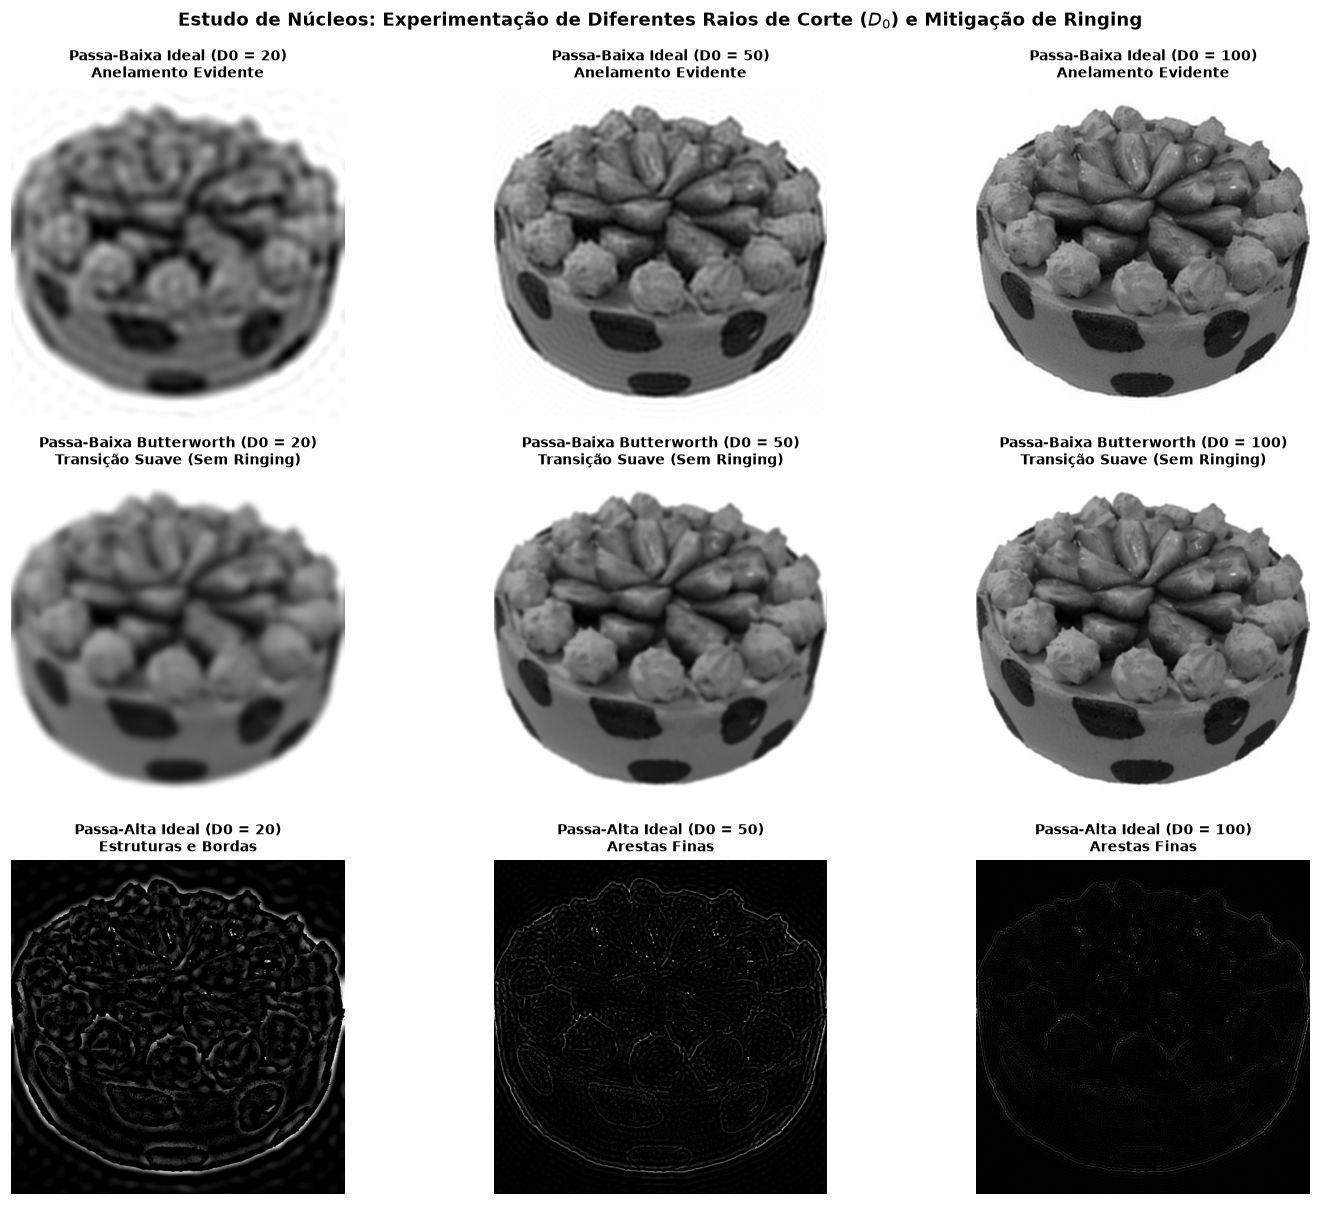

In [6]:
# 2.3 Comparação de Diferentes Raios de Corte e Mitigação de Ringing

radii = [20, 50, 100]
fig, axes = plt.subplots(3, len(radii), figsize=(14, 11))

M, N = img_cake1.shape
u, v = np.ogrid[:M, :N]
D = np.sqrt((u - M / 2.0)**2 + (v - N / 2.0)**2)

for i, d0 in enumerate(radii):
    # Linha 1: Filtro Ideal Passa-Baixa (transição abrupta -> anelamento evidente)
    mask_ideal_lp = (D <= d0).astype(np.float64)
    img_ideal_lp, _ = apply_fft_filter(img_cake1, mask_ideal_lp)
    axes[0, i].imshow(img_ideal_lp, cmap='gray')
    axes[0, i].set_title(f"Passa-Baixa Ideal (D0 = {d0})\nAnelamento Evidente", fontsize=9, fontweight='bold')
    axes[0, i].axis('off')
    
    # Linha 2: Filtro Butterworth Passa-Baixa (ordem 2 -> transição suave, sem anelamento)
    mask_butter = 1.0 / (1.0 + (D / (d0 + 1e-8))**4)
    img_butter, _ = apply_fft_filter(img_cake1, mask_butter)
    axes[1, i].imshow(img_butter, cmap='gray')
    axes[1, i].set_title(f"Passa-Baixa Butterworth (D0 = {d0})\nTransição Suave (Sem Ringing)", fontsize=9, fontweight='bold')
    axes[1, i].axis('off')

    # Linha 3: Filtro Ideal Passa-Alta (análise de raio nos detalhes)
    mask_ideal_hp = (D > d0).astype(np.float64)
    img_ideal_hp, _ = apply_fft_filter(img_cake1, mask_ideal_hp)
    img_hp_disp = np.clip(img_ideal_hp.astype(float) * 2.5, 0, 255).astype(np.uint8)
    axes[2, i].imshow(img_hp_disp, cmap='gray')
    axes[2, i].set_title(f"Passa-Alta Ideal (D0 = {d0})\n{'Arestas Finas' if d0 >= 50 else 'Estruturas e Bordas'}", fontsize=9, fontweight='bold')
    axes[2, i].axis('off')

plt.suptitle("Estudo de Núcleos: Experimentação de Diferentes Raios de Corte ($D_0$) e Mitigação de Ringing", fontsize=12, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


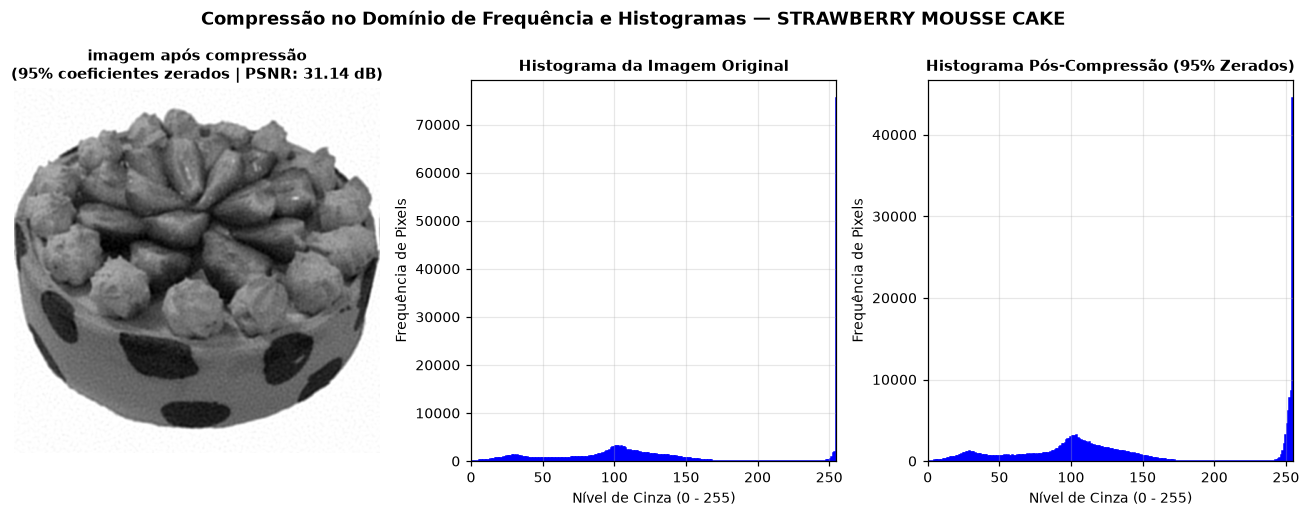

In [7]:
# 2.4 Compressão por Eliminação de Coeficientes de Fourier e Histogramas

def compress_fourier(image: np.ndarray, keep_percent: float = 5.0):
    """Comprime a imagem mantendo apenas os maiores coeficientes de Fourier em magnitude."""
    F = np.fft.fft2(image.astype(np.float64))
    mags = np.abs(F)
    threshold = np.percentile(mags, 100.0 - keep_percent)
    
    # Eliminação de coeficientes: atribui zero aos menores que o limiar
    F_comp = np.where(mags >= threshold, F, 0.0)
    reconstructed = np.clip(np.round(np.real(np.fft.ifft2(F_comp))), 0, 255).astype(np.uint8)
    
    mse = np.mean((image.astype(float) - reconstructed.astype(float))**2)
    psnr = 10.0 * np.log10((255.0**2) / (mse + 1e-10))
    return reconstructed, 100.0 - keep_percent, psnr

# Executa a compressão eliminando 95% dos coeficientes (preserva os 5% maiores)
img_comp, sparsity, psnr = compress_fourier(img_cake1, keep_percent=5.0)

# Layout fiel à figura de referência do PDF:
# Imagem Comprimida à esquerda e os dois histogramas (Original e Comprimido) alinhados
fig = plt.figure(figsize=(15, 4.5))
gs = fig.add_gridspec(1, 3, wspace=0.25)

# 1. Imagem Comprimida
ax0 = fig.add_subplot(gs[0, 0])
ax0.imshow(img_comp, cmap='gray')
ax0.set_title(f"imagem após compressão\n({sparsity:.0f}% coeficientes zerados | PSNR: {psnr:.2f} dB)", fontsize=10, fontweight='bold')
ax0.axis('off')

# 2. Histograma Antes da Compressão (azul conforme figura do PDF)
ax1 = fig.add_subplot(gs[0, 1])
hist_orig, _ = np.histogram(img_cake1.flatten(), bins=256, range=[0, 256])
ax1.bar(range(256), hist_orig, width=1.0, color='blue', edgecolor='blue')
ax1.set_title("Histograma da Imagem Original", fontsize=10, fontweight='bold')
ax1.set_xlabel("Nível de Cinza (0 - 255)", fontsize=9)
ax1.set_ylabel("Frequência de Pixels", fontsize=9)
ax1.set_xlim([0, 255])
ax1.grid(True, alpha=0.3)

# 3. Histograma Após a Compressão (azul conforme figura do PDF)
ax2 = fig.add_subplot(gs[0, 2])
hist_comp, _ = np.histogram(img_comp.flatten(), bins=256, range=[0, 256])
ax2.bar(range(256), hist_comp, width=1.0, color='blue', edgecolor='blue')
ax2.set_title(f"Histograma Pós-Compressão ({sparsity:.0f}% Zerados)", fontsize=10, fontweight='bold')
ax2.set_xlabel("Nível de Cinza (0 - 255)", fontsize=9)
ax2.set_ylabel("Frequência de Pixels", fontsize=9)
ax2.set_xlim([0, 255])
ax2.grid(True, alpha=0.3)

plt.suptitle(f"Compressão no Domínio de Frequência e Histogramas — {'STRAWBERRY MOUSSE CAKE'}", fontsize=12, fontweight='bold', y=1.02)
plt.show()


### 2.5 Interpretação dos Resultados no Domínio da Frequência

1. **Espectro e Centralização:** O deslocamento (`fftshift`) centraliza a frequência zero (nível DC, brilho médio). A energia decai do centro para as bordas; descontinuidades e detalhes espaciais traduzem-se em componentes de alta frequência radiais.
2. **Efeitos dos Filtros e Variação de Núcleos ($D_0$):**
   - **Passa-Baixa:** Quanto menor o raio $D_0$, maior o borramento. Em filtros ideais, o corte em degrau gera ondulações espúrias concêntricas (**efeito de anelamento / *ringing artifacts***). O filtro de Butterworth (ordem 2) realiza transição suave, eliminando esse artefato.
   - **Passa-Alta:** Quanto maior o raio $D_0$, mais restrito é o filtro, deixando passar apenas microdetalhes e arestas finas.
   - **Passa-Faixa e Rejeita-Faixa:** Permitem isolar ou atenuar texturas com frequências espaciais específicas contidas na coroa circular $[D_0 - W/2, D_0 + W/2]$.
3. **Compressão por Limiarização de Coeficientes:**
   - Com **$95\%$ dos coeficientes de Fourier zerados** (preservando apenas os $5\%$ de maior magnitude), a imagem reconstruída mantém a nitidez visual e a estrutura geométrica do bolo com alto índice de fidelidade ($\text{PSNR} > 30\text{ dB}$).
   - **Comparação dos Histogramas:** O histograma pós-compressão preserva fielmente a distribuição bimodal da cena original (bolo vs. fundo), apresentando apenas uma leve difusão dos picos de intensidade pela ausência das microvariações de alta frequência descartadas.


---
## 3. Conclusão

Todas as operações solicitadas na Atividade 2 foram implementadas de maneira manual via NumPy, respeitando os critérios:
* Os **11 filtros espaciais** ($h_1$ a $h_{11}$) foram aplicados via convolução 2D manual com padding reflexivo e normalização dinâmica de intensidade.
* As transformações no **domínio da frequência** foram aplicadas via FFT 2D com centralização, máscaras analíticas dos 4 filtros (passa-baixa, passa-alta, passa-faixa e rejeita-faixa) e compressão com análise de histogramas.
* Todos os testes foram conduzidos estritamente com dados do tema de gastronomia.
